# Give Me Some Credit

Proyecto final de Machine Learning. Primera revisión de datos y diccionario. Los archivos se leen sin modificar los originales.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

SEED = 42
TARGET = "SeriousDlqin2yrs"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cs-training.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Abre este notebook desde la carpeta GiveMeSomeCredit.")
print("Proyecto:", ROOT)

Proyecto: /Users/lenytacuri/GiveMeSomeCredit


In [2]:
train = pd.read_csv(ROOT / "cs-training.csv", index_col=0)
test = pd.read_csv(ROOT / "cs-test.csv", index_col=0)
dictionary = pd.read_excel(ROOT / "Data Dictionary.xls", header=1)
print("Entrenamiento:", train.shape)
print("Prueba:", test.shape)
display(dictionary)
display(train.head())

Entrenamiento: (150000, 11)
Prueba: (101503, 11)


,Variable Name,Description,Type
0,SeriousDlqin2yrs,Person experienced 90 days past due delinquenc...,Y/N
1,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lin...,percentage
2,age,Age of borrower in years,integer
3,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days p...,integer
4,DebtRatio,"Monthly debt payments, alimony,living costs di...",percentage
5,MonthlyIncome,Monthly income,real
6,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loa...,integer
7,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or m...,integer
8,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans inclu...,integer
9,NumberOfTime60-89DaysPastDueNotWorse,Number of times borrower has been 60-89 days p...,integer


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## Calidad de los datos

La primera columna de los CSV se usa como identificador, no como predictor. Revisar faltantes, tipos y valores extremos antes de decidir su tratamiento.

In [3]:
display(train.dtypes.to_frame("tipo"))
display(train.isna().sum().sort_values(ascending=False).to_frame("faltantes"))
display(train.describe().T)
print("Identificadores únicos:", train.index.is_unique)
print("Etiquetas disponibles en test:", test[TARGET].notna().sum() if TARGET in test else 0)

,tipo
SeriousDlqin2yrs,int64
RevolvingUtilizationOfUnsecuredLines,float64
age,int64
NumberOfTime30-59DaysPastDueNotWorse,int64
DebtRatio,float64
MonthlyIncome,float64
NumberOfOpenCreditLinesAndLoans,int64
NumberOfTimes90DaysLate,int64
NumberRealEstateLoansOrLines,int64
NumberOfTime60-89DaysPastDueNotWorse,int64


,faltantes
MonthlyIncome,29731
NumberOfDependents,3924
SeriousDlqin2yrs,0
RevolvingUtilizationOfUnsecuredLines,0
age,0
NumberOfTime30-59DaysPastDueNotWorse,0
DebtRatio,0
NumberOfOpenCreditLinesAndLoans,0
NumberOfTimes90DaysLate,0
NumberRealEstateLoansOrLines,0


,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


Identificadores únicos: True
Etiquetas disponibles en test: 0


,cantidad,proporción
SeriousDlqin2yrs,,
0,139974,0.93316
1,10026,0.06684


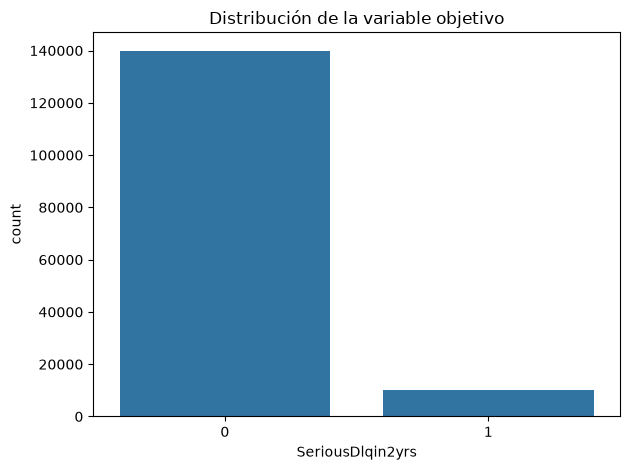

In [4]:
display(train[TARGET].value_counts().rename("cantidad").to_frame().join(train[TARGET].value_counts(normalize=True).rename("proporción")))
sns.countplot(data=train, x=TARGET)
plt.title("Distribución de la variable objetivo")
plt.tight_layout()
plt.show()

## Dataset splitting

El dataset de test ("cs-test.csv") que me descargué de Kaggle no tiene la variable respuesta 'SeriousDlqin2yrs', por lo cual no podré usar este dataset realmente como test, por lo que definiremos un nuevo dataset, el cual dividiremos en train y test. Este dataset será el que vino en el archivo: "cs-training.csv". Adicionalmente como descubrimos en la exploración que 'MontlyIncome' y 'NumberOfDependents' tienen un porcentaje muy elevado de datos faltantes, decidí eliminar las filas sin observaciones en 'MontlyIncome', que corresponden a 29 731 filas, o el 19,82 % del dataset.

In [8]:
from sklearn.model_selection import train_test_split

df = train.copy()

df = df.dropna(subset=["MonthlyIncome"])

X = df.drop(columns=TARGET)  # Variables predictoras
y = df[TARGET]              # Variable objetivo

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (96215, 10)
y_train: (96215,)
X_test: (24054, 10)
y_test: (24054,)


## Feature selection

Antes de entrenar el modelo definitivo, exploraré las relaciones entre las variables predictoras y evaluaré una técnica de selección de características (*feature selection*). Consideraré tres enfoques: métodos de filtrado (*filter*), que utilizan criterios estadísticos; métodos *wrapper*, que comparan subconjuntos de variables mediante el desempeño de modelos; y métodos integrados (*embedded*), como la regularización L1, que pueden llevar algunos coeficientes a cero durante el entrenamiento.

Como análisis inicial, examinaré la matriz de correlación, ya que las variables tienen distintas unidades y escalas. Esta matriz permitirá explorar relaciones lineales y posibles redundancias, aunque por sí solas no determinan qué variables son útiles para predecir la variable objetivo.

La selección se realizará exclusivamente con los datos de entrenamiento. Si utilizo validación cruzada, incorporaré este paso dentro de cada partición, manteniendo el conjunto de prueba reservado para la evaluación final.

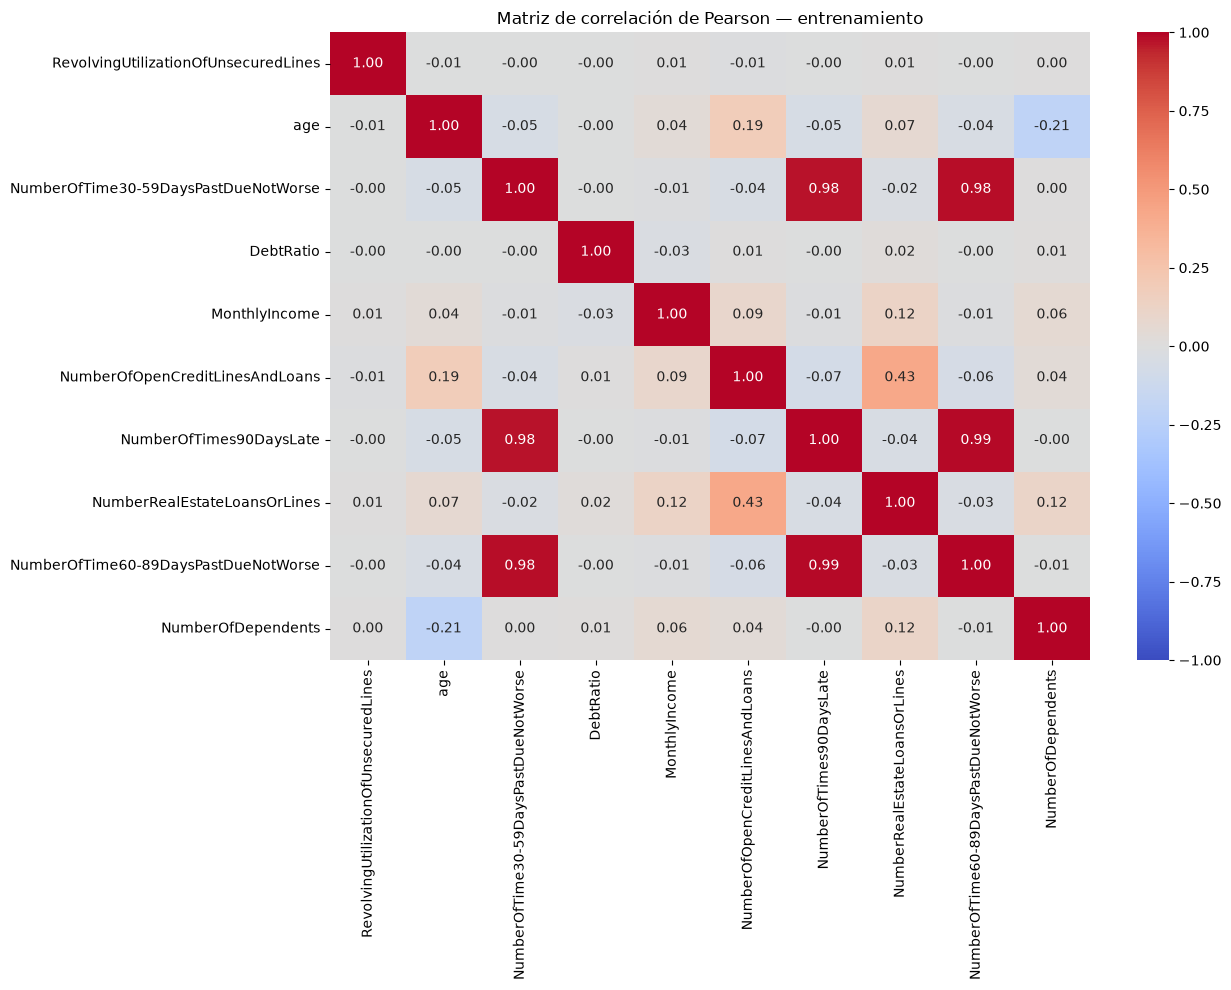

In [10]:
# Calcular las matrices
corr_matrix = X_train.corr(method="pearson")

# Dibujar la matriz de correlación
plt.figure(figsize=(13, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlación de Pearson — entrenamiento")
plt.tight_layout()
plt.show()

## Distribución y asimetría


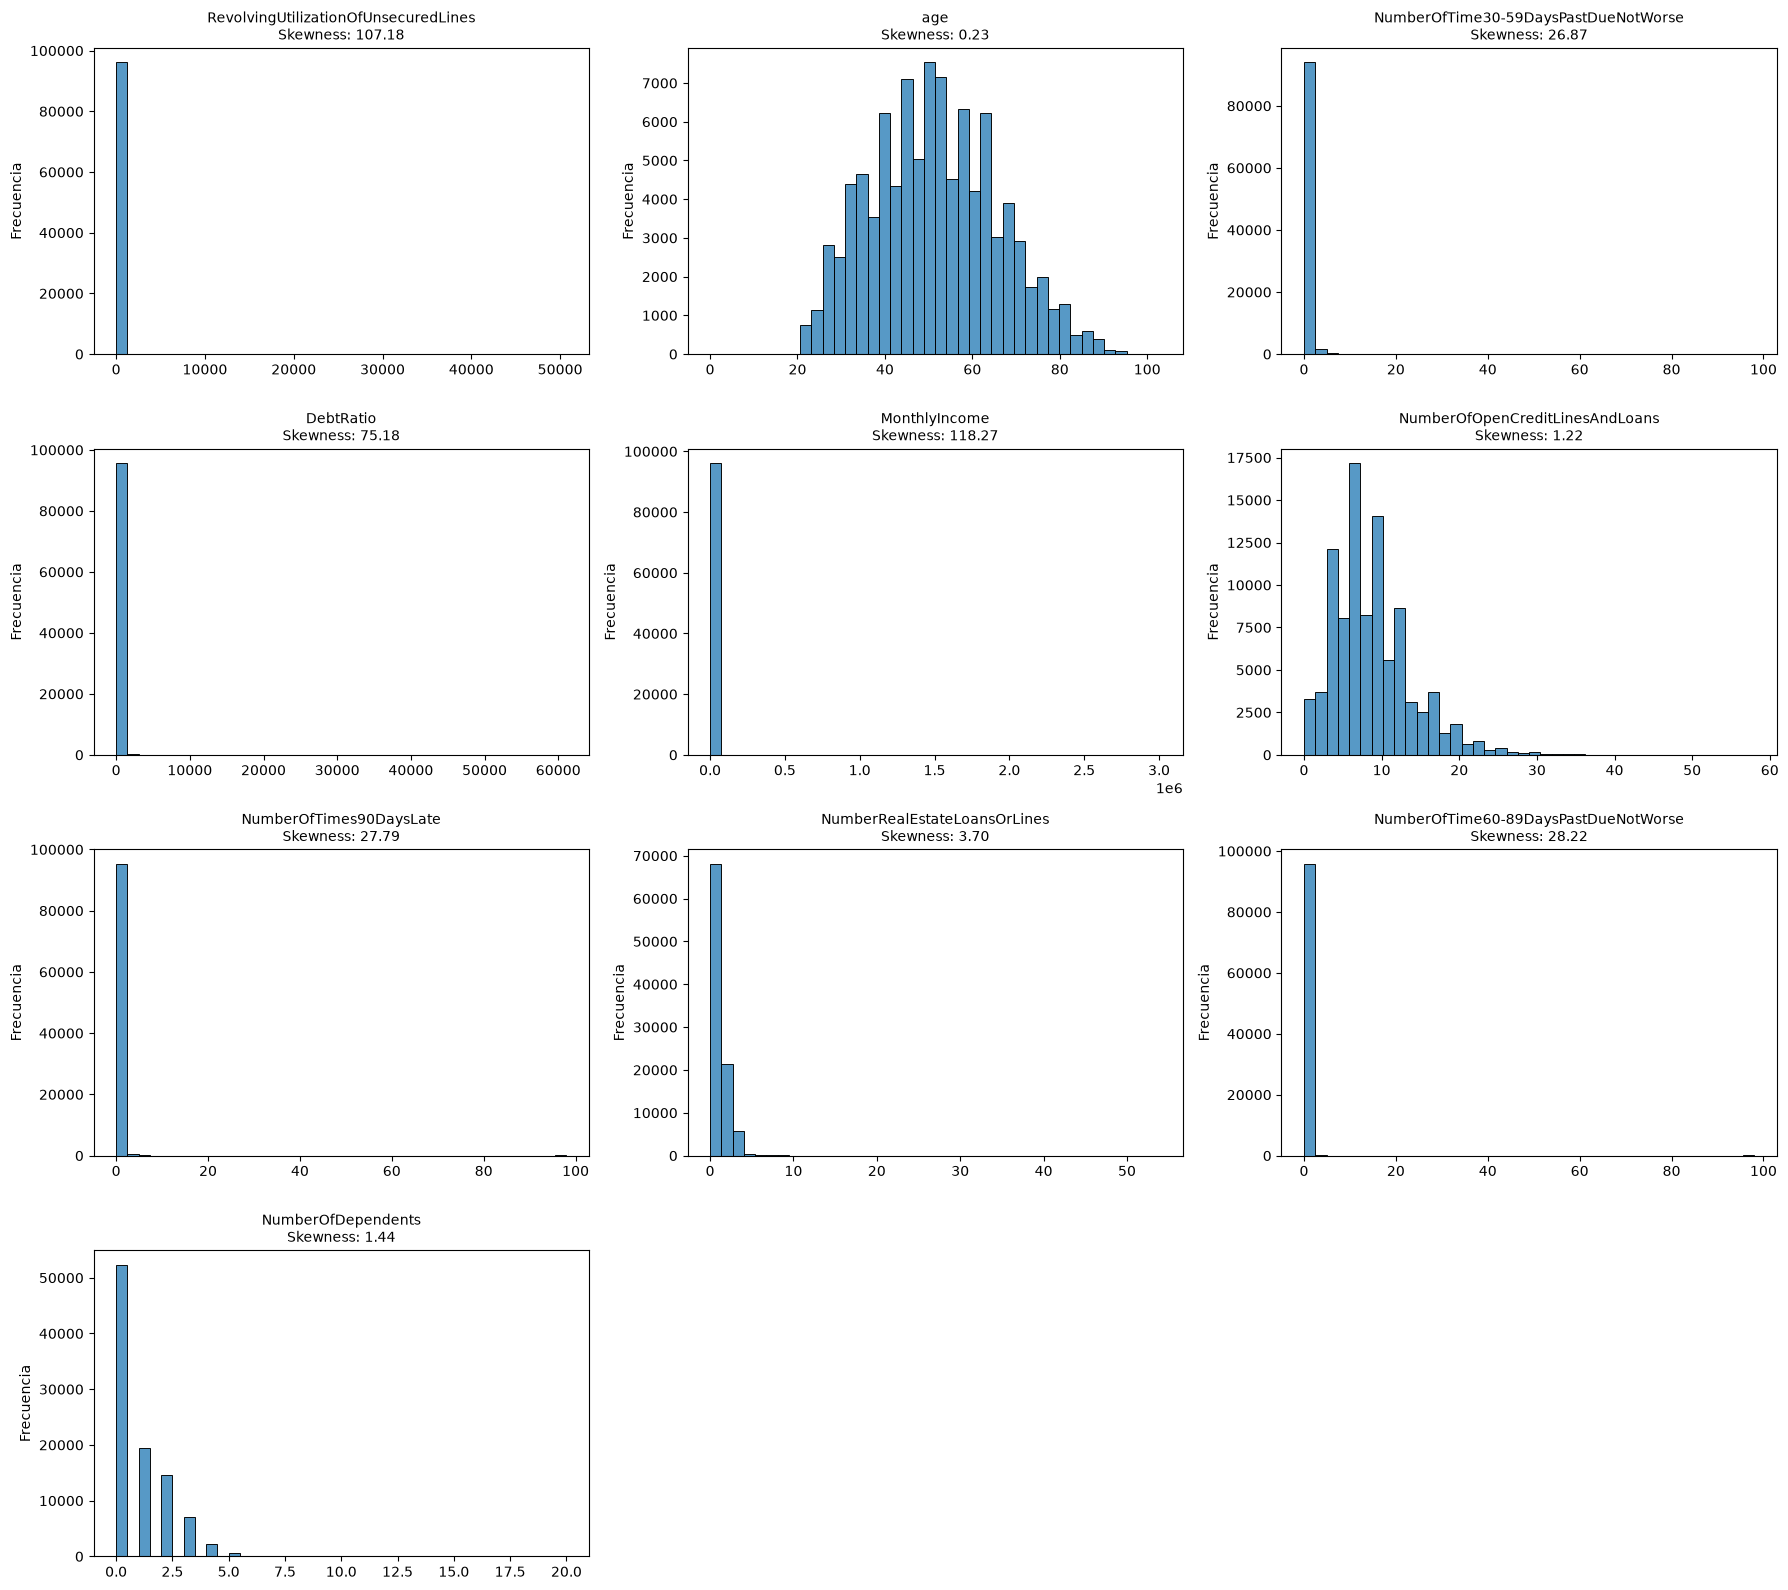

In [11]:
# Asimetría de cada variable
skewness = X_train.skew()

# Crear una cuadrícula de gráficos
n_cols = 3
n_rows = (len(X_train.columns) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4 * n_rows)
)

axes = axes.flatten()

for ax, feature in zip(axes, X_train.columns):
    sns.histplot(
        data=X_train,
        x=feature,
        bins=40,
        ax=ax
    )

    ax.set_title(
        f"{feature}\nSkewness: {skewness[feature]:.2f}",
        fontsize=10
    )
    ax.set_xlabel("")
    ax.set_ylabel("Frecuencia")

# Ocultar los espacios sobrantes
for ax in axes[len(X_train.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Estadísticos de mi nuevo dataset sin valores ausentes

Estos estadísiticos los estoy generando porque en la gráfica anterior vi que la mayoría de features tiene un 'skewness' super alto, por lo que intuyo que deben existir outliers en estas features. Llaman mi atención especialmente cuatro features: 'RevolvingUtilizationOfUnsecuredLines', 'NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTimes90DaysLate', y 'NumberOfTime60-89DaysPastDueNotWorse'. Estas features tienen valores máximos que no hacen sentido en el contexto de este análisis, y es por esto que abajo imprimo los 10 valores más altos de cada uno, para tener una idea de qué tan grande es la desviación.

In [12]:
display(X_train.describe().T)

for feature in X_train.columns:
    print(f"\n{'=' * 60}")
    print(f"Feature: {feature}")
    display(X_train[feature].nlargest(10).to_frame())

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,96215.0,6.020631,258.550660,0.0,0.035507,0.179148,0.581634,50708.0
age,96215.0,51.304464,14.404538,0.0,41.000000,51.000000,61.000000,103.0
NumberOfTime30-59DaysPastDueNotWorse,96215.0,0.378558,3.478053,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,96215.0,26.836417,447.741573,0.0,0.143736,0.296494,0.483735,61106.5
MonthlyIncome,96215.0,6677.168934,14782.576908,0.0,3400.000000,5400.000000,8231.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,96215.0,8.772593,5.180850,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,96215.0,0.210456,3.444836,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,96215.0,1.056363,1.151067,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,96215.0,0.186218,3.427097,0.0,0.000000,0.000000,0.000000,98.0
NumberOfDependents,96215.0,0.854503,1.152136,0.0,0.000000,0.000000,2.000000,20.0



Feature: RevolvingUtilizationOfUnsecuredLines


,RevolvingUtilizationOfUnsecuredLines
85490,50708.0
149161,22000.0
149280,20514.0
117316,18300.0
21979,17441.0
71706,13400.0
58853,11843.0
13670,10209.0
123072,10151.0
50696,9684.0



Feature: age


,age
19885,103
25562,102
96451,102
93814,101
116130,101
57527,99
108365,98
9871,98
142765,98
39705,97


...

,NumberRealEstateLoansOrLines
30588,54
65729,29
18260,26
68910,25
123747,25
62193,23
31518,21
98387,20
141115,20
123342,19



Feature: NumberOfTime60-89DaysPastDueNotWorse


,NumberOfTime60-89DaysPastDueNotWorse
9649,98
56603,98
141072,98
47560,98
27477,98
142128,98
70097,98
129695,98
88079,98
8174,98



Feature: NumberOfDependents


,NumberOfDependents
6300,20.0
128035,13.0
123912,10.0
12983,10.0
22699,10.0
39096,10.0
122769,9.0
137561,9.0
44849,9.0
142804,9.0


## Dataset desbalanceado

Debido al contexto del dataset, es necesario reconocer que hay un desbalance entre las clases, y por lo tanto puede ser necesario implementar un método de balanceo. Para resolver esto, utilizaré la técnica del submuestreo, pero la aplicaré en el entrenamiento de cada durante Cross Validation.  

In [13]:
print (y_train.value_counts().sort_index())

SeriousDlqin2yrs
0    89529
1     6686
Name: count, dtype: int64


## Primera técnica de ML: Regresión logística

In [ ]:
# 1. Pipeline: cada paso se ajusta dentro de cada fold.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

log_features = [column for column in X_train.columns if column != "age"]

log_transform = ColumnTransformer(
    [("log", FunctionTransformer(np.log1p), log_features)],
    remainder="passthrough",  # age no se transforma con log, pero sí se escala.
)

pipeline_lr = Pipeline([
    ("log", log_transform),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_classif)),
    ("sampler", RandomUnderSampler(random_state=SEED)),
    ("model", LogisticRegression(solver="lbfgs", max_iter=2000)),
])

In [19]:
# 2. Métricas, validación cruzada e hiperparámetros.
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
}
# predict usa el umbral habitual de 0.5 para las métricas de cada clase.
for label in [0, 1]:
    scoring[f"precision_class_{label}"] = make_scorer(precision_score, pos_label=label, zero_division=0)
    scoring[f"recall_class_{label}"] = make_scorer(recall_score, pos_label=label, zero_division=0)
    scoring[f"f1_class_{label}"] = make_scorer(f1_score, pos_label=label, zero_division=0)

cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEED)
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "selector__k": [5, 7, 9, "all"],
}

RESULTS_DIR = ROOT / "results" / "regresion_logistica"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# 3. Entrenamiento: ejecutar esta celda para iniciar una nueva búsqueda.
# Son 20 combinaciones x 100 folds. X_test se reserva para el final.
search_lr = GridSearchCV(
    pipeline_lr,
    param_grid=param_grid,
    scoring=scoring,
    refit="roc_auc",
    cv=cv,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
    verbose=1,
)
search_lr.fit(X_train, y_train)

Mejores parámetros: {'model__C': 100.0, 'selector__k': 'all'}
ROC-AUC de validación: 0.8463


,param_model__C,param_selector__k,mean_test_roc_auc,mean_test_average_precision,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_precision_class_0,mean_test_recall_class_0,mean_test_f1_class_0,mean_test_precision_class_1,mean_test_recall_class_1,mean_test_f1_class_1
19,100.00,all,0.846255,0.353397,0.813109,0.764666,0.974165,0.820928,0.890978,0.228320,0.708403,0.345232
15,10.00,all,0.846255,0.353398,0.813116,0.764670,0.974165,0.820936,0.890983,0.228327,0.708403,0.345241
11,1.00,all,0.846254,0.353400,0.813175,0.764687,0.974164,0.821001,0.891021,0.228385,0.708373,0.345303
7,0.10,all,0.846249,0.353458,0.813709,0.764566,0.974107,0.821641,0.891374,0.228802,0.707491,0.345673
3,0.01,all,0.846086,0.353626,0.818450,0.763979,0.973699,0.827243,0.894490,0.232732,0.700715,0.349307
14,10.00,9,0.846049,0.353015,0.812519,0.764501,0.974173,0.820269,0.890592,0.227770,0.708733,0.344637
18,100.00,9,0.846049,0.353015,0.812513,0.764498,0.974173,0.820263,0.890588,0.227763,0.708733,0.344629
10,1.00,9,0.846049,0.353019,0.812566,0.764512,0.974172,0.820322,0.890622,0.227814,0.708703,0.344685
6,0.10,9,0.846044,0.353070,0.813088,0.764399,0.974117,0.820947,0.890968,0.228215,0.707850,0.345041
2,0.01,9,0.845917,0.353311,0.818064,0.764034,0.973734,0.826785,0.894236,0.232417,0.701283,0.349018


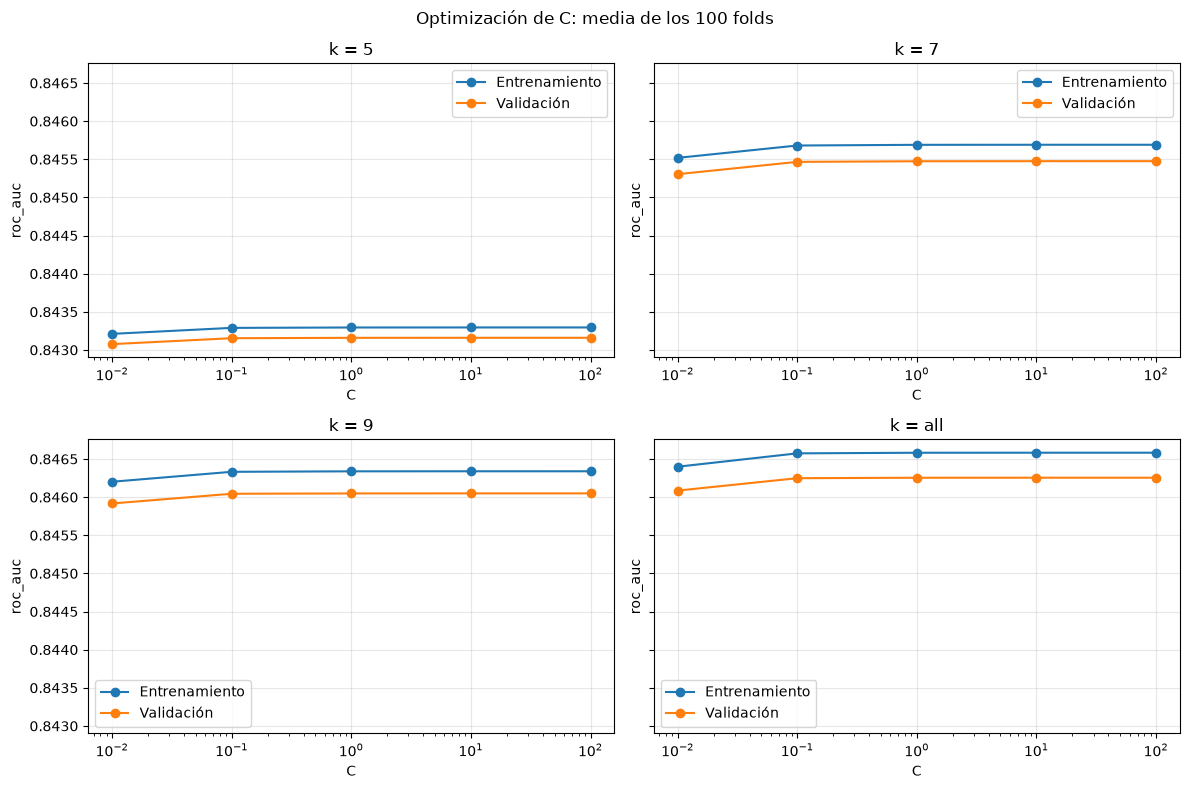

In [20]:
# 4. Resultados y optimización de C (esta celda no entrena).
results_lr = pd.DataFrame(search_lr.cv_results_)
results_lr.to_csv(RESULTS_DIR / "gridsearch_resultados.csv", index=False)
# El CSV incluye split0_train_roc_auc, split0_test_roc_auc, etc.
# Aquí "test" significa validación del fold, NO nuestro X_test.

print("Mejores parámetros:", search_lr.best_params_)
print("ROC-AUC de validación:", round(search_lr.best_score_, 4))
summary_columns = ["param_model__C", "param_selector__k"] + [
    f"mean_test_{metric}" for metric in scoring
]
display(results_lr[summary_columns].sort_values("mean_test_roc_auc", ascending=False))

metric = "roc_auc"  # Puedes cambiar a precision_class_1, recall_class_1, etc.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, k in zip(axes.flat, param_grid["selector__k"]):
    curve = results_lr[results_lr["param_selector__k"] == k].sort_values("param_model__C")
    for subset, label in [("train", "Entrenamiento"), ("test", "Validación")]:
        ax.plot(curve["param_model__C"], curve[f"mean_{subset}_{metric}"], "o-", label=label)
    ax.set(xscale="log", xlabel="C", ylabel=metric, title=f"k = {k}")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Optimización de C: media de los 100 folds")
fig.tight_layout()
fig.savefig(RESULTS_DIR / f"optimizacion_C_{metric}.png", dpi=150)
plt.show()

In [ ]:
# 5. Curva de aprendizaje: requiere nuevos ajustes al variar el tamaño de muestra.
# C y k quedan fijos en los valores elegidos; el pipeline se reajusta en cada fold.
from sklearn.model_selection import learning_curve

learning_sizes, learning_train, learning_validation = learning_curve(
    search_lr.best_estimator_, X_train, y_train,
    train_sizes=[0.10, 0.25, 0.50, 0.75, 1.0],
    cv=cv,
    scoring="roc_auc",
    shuffle=True,
    random_state=SEED,
    n_jobs=-1,
    error_score="raise",
)

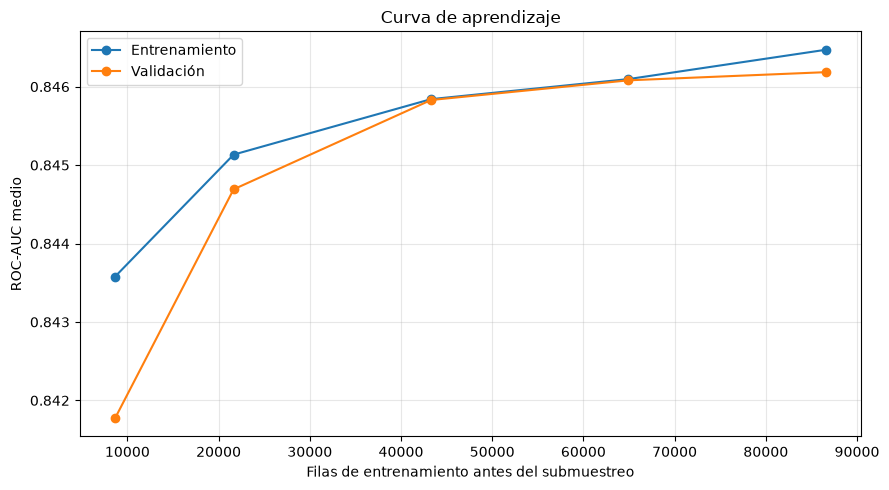

Resultados guardados en: /Users/lenytacuri/GiveMeSomeCredit/results/regresion_logistica


In [21]:
# 6. Guardar y dibujar la curva de aprendizaje (sin reentrenar).
# En los CSV, cada fila es un tamaño y cada columna es un fold (0 a 99).
pd.DataFrame(learning_train, index=learning_sizes).to_csv(
    RESULTS_DIR / "aprendizaje_train.csv", index_label="n_training_rows"
)
pd.DataFrame(learning_validation, index=learning_sizes).to_csv(
    RESULTS_DIR / "aprendizaje_validation.csv", index_label="n_training_rows"
)

plt.figure(figsize=(9, 5))
plt.plot(learning_sizes, learning_train.mean(axis=1), "o-", label="Entrenamiento")
plt.plot(learning_sizes, learning_validation.mean(axis=1), "o-", label="Validación")
plt.xlabel("Filas de entrenamiento antes del submuestreo")
plt.ylabel("ROC-AUC medio")
plt.title("Curva de aprendizaje")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "curva_aprendizaje.png", dpi=150)
plt.show()
# Es un diagnóstico tras elegir C y k, no una evaluación independiente en test.
print("Resultados guardados en:", RESULTS_DIR)